# Modelo de priorización de riesgo de secuestro en municipios de Colombia

**Proyecto de Grado II (203008071)** · Especialización en Ciencia de Datos y Analítica · UNAD

Autor: Jorge Enrique Vargas Soto · Asesor: Isaac Esteban Camargo Freile

Este cuaderno es el prototipo reproducible del proyecto. Estima, para cada municipio de Colombia y cada mes, la probabilidad de que se registre al menos un secuestro, y clasifica los municipios en niveles de riesgo Alto, Medio y Bajo para apoyar la priorización de los equipos de seguridad corporativa.

**Datos de entrada** (no se incluyen en el repositorio, se descargan de las fuentes oficiales y se guardan en la carpeta `Archivos Excel datos actualizados 18 de Agosto de 2026`):

- `SECUESTRO.xlsx`, del Ministerio de Defensa Nacional, descargado el 18 de agosto de 2026.
- `DIVIPOLA-_Códigos_municipios_20261003.xlsx`, catálogo DIVIPOLA del DANE.
- `MGN2025_MPIO_GRAFICO/MGN_ADM_MPIO_GRAFICO.shp`, capa municipal del Marco Geoestadístico Nacional 2025 del DANE.

**Orden del cuaderno.** Sigue el mismo orden del documento: (1) fuentes y universo, (2) exploración y autocorrelación espacial, (3) panel municipio-mes, (4) variables, (5) partición temporal, (6) líneas base, (7) regresión logística, (8) bosque aleatorio, (9) calibración y niveles de riesgo, (10) dependencia espacial de los errores y (11) evaluación final en prueba.

Las celdas deben ejecutarse en orden, de arriba a abajo. Se usa la semilla 42 en todos los pasos aleatorios para que los resultados se puedan repetir.

In [1]:
import os
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from libpysal import weights
from esda.moran import Moran

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, log_loss)

## 1. Fuentes de datos y universo de análisis

### 1.1 Carga del archivo de secuestro

Cargamos el archivo original del Ministerio de Defensa en un DataFrame llamado `df_raw`.

`df_raw` es la copia fiel del archivo y nunca se modifica. Todo lo demás se construye a partir de ella.

In [2]:
df_raw = pd.read_excel('Archivos Excel datos actualizados 18 de Agosto de 2026/SECUESTRO.xlsx')
print(df_raw.shape)
df_raw.info()

(10334, 7)
<class 'pandas.DataFrame'>
RangeIndex: 10334 entries, 0 to 10333
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   FECHA_HECHO           10334 non-null  datetime64[us]
 1   COD_DEPTO             10334 non-null  int64         
 2   DEPARTAMENTO          10334 non-null  str           
 3   COD_MUNI              10334 non-null  int64         
 4   MUNICIPIO             10334 non-null  str           
 5   DESCRIPCION CONDUCTA  10334 non-null  str           
 6   CANTIDAD              10334 non-null  int64         
dtypes: datetime64[us](1), int64(3), str(3)
memory usage: 565.3 KB


### 1.2 Tamaño y rango del archivo

Medimos el archivo con cuatro cifras: rango de fechas, número de registros, número de hechos y número de municipios distintos.

Un registro (una fila) puede agrupar varios secuestros, que se cuentan en `CANTIDAD`. Por eso distinguimos entre registros y hechos.


In [3]:
print("Fecha mínima:", df_raw['FECHA_HECHO'].min())
print("Fecha máxima:", df_raw['FECHA_HECHO'].max())
print("Registros:", len(df_raw))
print("Hechos (suma de CANTIDAD):", df_raw['CANTIDAD'].sum())
print("Códigos de municipio distintos:", df_raw['COD_MUNI'].nunique())

Fecha mínima: 2003-01-01 00:00:00
Fecha máxima: 2026-07-30 00:00:00
Registros: 10334
Hechos (suma de CANTIDAD): 10766
Códigos de municipio distintos: 841


### 1.3 Hechos por año

Sumamos los hechos (`CANTIDAD`) por año y los graficamos.

Para ver cómo se distribuye el fenómeno en el tiempo y decidir desde qué año tiene sentido modelar.


FECHA_HECHO
2003    2121
2004    1440
2005     800
2006     687
2007     521
2008     437
2009     213
2010     282
2011     305
2012     305
2013     299
2014     288
2015     213
2016     207
2017     195
2018     176
2019     163
2020     162
2021     160
2022     223
2023     338
2024     313
2025     701
2026     217
Name: CANTIDAD, dtype: int64

Proporción de hechos antes de 2010: 57.8%


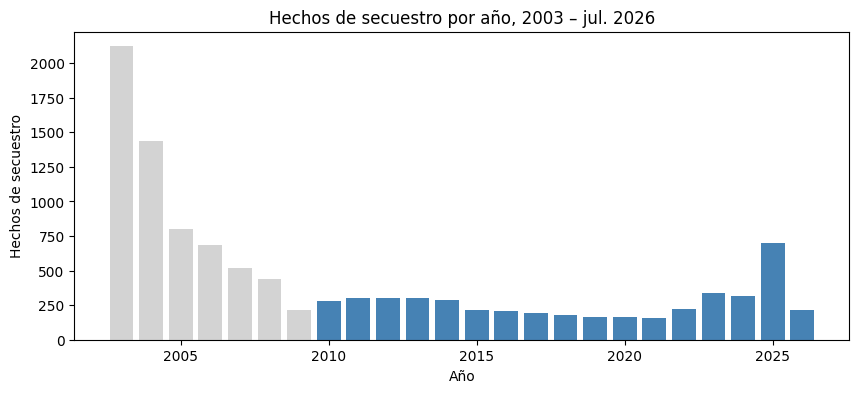

In [4]:
anio = df_raw['FECHA_HECHO'].dt.year
hechos_anio = df_raw.groupby(anio)['CANTIDAD'].sum()
print(hechos_anio)

antes_2010 = hechos_anio[hechos_anio.index < 2010].sum() / hechos_anio.sum()
print(f"\nProporción de hechos antes de 2010: {antes_2010:.1%}")

colores = ['lightgray' if a < 2010 else 'steelblue' for a in hechos_anio.index]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hechos_anio.index, hechos_anio.values, color=colores)
ax.set_xlabel('Año')
ax.set_ylabel('Hechos de secuestro')
ax.set_title('Hechos de secuestro por año, 2003 – jul. 2026')
plt.show()

### 1.4 Filtro del periodo de modelado

Nos quedamos solo con los registros desde el 1 de enero de 2010 y los guardamos en `df_2010`.

Los años anteriores muestran un nivel de hechos distinto (gráfico de 1.3) y no representan el comportamiento actual.

In [5]:
df_2010 = df_raw[df_raw['FECHA_HECHO'].dt.year >= 2010].copy()

print("Registros:", len(df_2010))
print("Hechos:", df_2010['CANTIDAD'].sum())
print("Códigos de municipio distintos:", df_2010['COD_MUNI'].nunique())
print("Meses del periodo:", len(pd.period_range('2010-01', '2026-07', freq='M')))

Registros: 4384
Hechos: 4547
Códigos de municipio distintos: 561
Meses del periodo: 199


### 1.5 Carga del catálogo DIVIPOLA

Cargamos el catálogo oficial del DANE con los códigos de departamentos y municipios en un DataFrame llamado `divipola`, y lo dejamos listo para cruzarlo con otras fuentes.

Es la lista oficial de municipios, independiente de si tuvieron eventos. Será la base para el universo de análisis. Hay dos ajustes necesarios: el código se lee como número y pierde el cero inicial, y las coordenadas usan coma decimal.


In [6]:
divipola = pd.read_excel('Archivos Excel datos actualizados 18 de Agosto de 2026/DIVIPOLA-_Códigos_municipios_20261003.xlsx')

divipola = divipola.rename(columns={
    'Código Departamento': 'COD_DEPTO',
    'Nombre Departamento': 'DEPARTAMENTO',
    'Código Municipio': 'COD_MUNI',
    'Nombre Municipio': 'MUNICIPIO',
    'Tipo: Municipio / Isla / Área no municipalizada': 'TIPO',
    'longitud': 'LON',
    'Latitud': 'LAT'
})

divipola['COD_MUNI'] = divipola['COD_MUNI'].astype(int).astype(str).str.zfill(5)
divipola['LON'] = divipola['LON'].astype(str).str.replace(',', '.').astype(float)
divipola['LAT'] = divipola['LAT'].astype(str).str.replace(',', '.').astype(float)

print(divipola.shape)
print(divipola['TIPO'].value_counts())
print("Códigos únicos:", divipola['COD_MUNI'].is_unique)

(1122, 7)
TIPO
Municipio                 1103
Área no municipalizada      18
Isla                         1
Name: count, dtype: int64
Códigos únicos: True


### 1.6 Carga de la capa municipal MGN 2025

Cargamos la capa municipal del Marco Geoestadístico Nacional (DANE, 2025) en un GeoDataFrame llamado `gdf`.

Aporta el área oficial de cada municipio en km² (`mpio_narea`), que necesitamos para normalizar, y el contorno de cada uno, que usaremos para los mapas.


In [7]:
gdf = gpd.read_file('Archivos Excel datos actualizados 18 de Agosto de 2026/MGN2025_MPIO_GRAFICO/MGN_ADM_MPIO_GRAFICO.shp')

print(gdf.shape)
print(gdf.columns.tolist())
print(gdf[['mpio_cdpmp', 'mpio_cnmbr', 'mpio_tipo', 'mpio_narea']].head())

(1122, 12)
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']
  mpio_cdpmp  mpio_cnmbr  mpio_tipo  mpio_narea
0      05001    MEDELLÍN  MUNICIPIO  374.741484
1      05002   ABEJORRAL  MUNICIPIO  506.959782
2      05004    ABRIAQUÍ  MUNICIPIO  296.974188
3      05021  ALEJANDRÍA  MUNICIPIO  128.856431
4      05030       AMAGÁ  MUNICIPIO   84.117145


### 1.7 Cruce de códigos entre DIVIPOLA, MGN y secuestro

Verificamos que los códigos de municipio coincidan entre las tres fuentes.

Vamos a unir las fuentes por código. Si algún código no aparece en alguna, perderíamos información o tendríamos municipios sin área.


In [8]:
cod_sec = pd.Series(df_raw['COD_MUNI'].astype(int).astype(str).str.zfill(5).unique())

print("DIVIPOLA en MGN:", divipola['COD_MUNI'].isin(gdf['mpio_cdpmp']).sum(), "de", len(divipola))
print("MGN en DIVIPOLA:", gdf['mpio_cdpmp'].isin(divipola['COD_MUNI']).sum(), "de", len(gdf))
print("Secuestro en DIVIPOLA:", cod_sec.isin(divipola['COD_MUNI']).sum(), "de", len(cod_sec))

DIVIPOLA en MGN: 1122 de 1122
MGN en DIVIPOLA: 1122 de 1122
Secuestro en DIVIPOLA: 837 de 841


### 1.8 Identificación de los códigos sin cruce

Averiguamos cuáles son los 4 códigos del archivo de secuestro que no están en DIVIPOLA, a qué municipio corresponden y cuántos hechos representan, tanto en el archivo completo como desde 2010.

Antes de excluirlos hay que saber qué son y cuánto pesan.


In [9]:
cod_no_enc = cod_sec[~cod_sec.isin(divipola['COD_MUNI'])].tolist()
print("Códigos sin cruce:", cod_no_enc)

# Archivo completo
cod_txt_raw = df_raw['COD_MUNI'].astype(int).astype(str).str.zfill(5)
sin_match = df_raw[cod_txt_raw.isin(cod_no_enc)]
print("\nArchivo completo -> Registros:", len(sin_match), "| Hechos:", sin_match['CANTIDAD'].sum())
print(sin_match.groupby(['COD_MUNI', 'DEPARTAMENTO', 'MUNICIPIO'])['CANTIDAD'].agg(['count', 'sum']))

# Desde 2010
cod_txt_2010 = df_2010['COD_MUNI'].astype(int).astype(str).str.zfill(5)
sin_2010 = df_2010[cod_txt_2010.isin(cod_no_enc)]
print("\nDesde 2010 -> Registros:", len(sin_2010), "| Hechos:", sin_2010['CANTIDAD'].sum())

Códigos sin cruce: ['41000', '50000', '70000', '95000']

Archivo completo -> Registros: 6 | Hechos: 6
                                      count  sum
COD_MUNI DEPARTAMENTO MUNICIPIO                 
41000    HUILA        SIN ESTABLECER      1    1
50000    META         SIN ESTABLECER      1    1
70000    SUCRE        SIN ESTABLECER      3    3
95000    GUAVIARE     SIN ESTABLECER      1    1

Desde 2010 -> Registros: 0 | Hechos: 0


### 1.9 Universo de análisis

Definimos el universo de modelado (municipios e isla del catálogo DIVIPOLA) y le agregamos el área oficial en km² tomada del MGN. Dejamos `df_sec` como la base de eventos del periodo de modelado.

El modelo necesita una lista completa de municipios, incluidos los que nunca tuvieron eventos, porque serán los casos negativos. Las 18 áreas no municipalizadas no son municipios y no registran hechos, así que se excluyen.

In [10]:
df_sec = df_2010.copy()

universo = divipola[divipola['TIPO'].isin(['Municipio', 'Isla'])].copy()
area = gdf[['mpio_cdpmp', 'mpio_narea']].rename(
    columns={'mpio_cdpmp': 'COD_MUNI', 'mpio_narea': 'AREA_KM2'})
universo = universo.merge(area, on='COD_MUNI', how='left')

print("Unidades del universo:", len(universo))
print("Áreas no municipalizadas excluidas:", (divipola['TIPO'] == 'Área no municipalizada').sum())
print("Unidades sin área:", universo['AREA_KM2'].isna().sum())

cod_sec_2010 = df_sec['COD_MUNI'].astype(int).astype(str).str.zfill(5)
print("Registros de df_sec fuera del universo:", (~cod_sec_2010.isin(universo['COD_MUNI'])).sum())
print("Municipios con al menos un hecho:", cod_sec_2010.nunique())

Unidades del universo: 1104
Áreas no municipalizadas excluidas: 18
Unidades sin área: 0
Registros de df_sec fuera del universo: 0
Municipios con al menos un hecho: 561


## 2. Exploración de los datos

### 2.1 Hechos por departamento

Sumamos los hechos de `df_sec` (2010 – jul. 2026) por departamento y graficamos los 10 con más hechos.

Para ver qué tan concentrado está el fenómeno a nivel departamental y qué territorios pesan más.

Departamentos con al menos un hecho: 31
                 DEPARTAMENTO  HECHOS  PORCENTAJE  ACUMULADO
COD_DEPTO                                                   
19                      CAUCA     583        12.8       12.8
5                   ANTIOQUIA     506        11.1       23.9
76            VALLE DEL CAUCA     490        10.8       34.7
54         NORTE DE SANTANDER     429         9.4       44.1
11                BOGOTA D.C.     349         7.7       51.8
81                     ARAUCA     344         7.6       59.4
52                     NARIÑO     260         5.7       65.1
50                       META     179         3.9       69.0
27                      CHOCO     126         2.8       71.8
25               CUNDINAMARCA     117         2.6       74.4


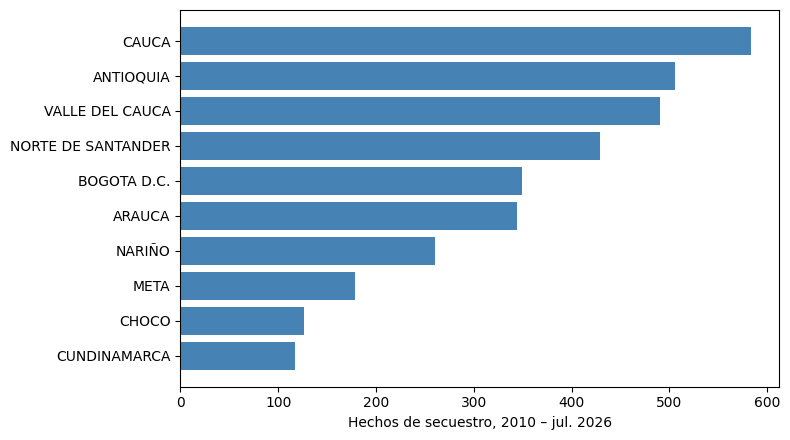

In [11]:
por_depto = (df_sec.groupby('COD_DEPTO')
             .agg(DEPARTAMENTO=('DEPARTAMENTO', 'first'), HECHOS=('CANTIDAD', 'sum'))
             .sort_values('HECHOS', ascending=False))
por_depto['PORCENTAJE'] = (por_depto['HECHOS'] / por_depto['HECHOS'].sum() * 100).round(1)
por_depto['ACUMULADO'] = por_depto['PORCENTAJE'].cumsum().round(1)

print("Departamentos con al menos un hecho:", len(por_depto))
print(por_depto.head(10))

top10 = por_depto.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10['DEPARTAMENTO'], top10['HECHOS'], color='steelblue')
ax.set_xlabel('Hechos de secuestro, 2010 – jul. 2026')
plt.tight_layout()
plt.savefig('fig2_hechos_por_departamento.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.2 Concentración municipal

Sumamos los hechos por municipio, listamos los 10 con más hechos y calculamos cuántos municipios se necesitan para acumular el 50 % de los hechos.

El modelo trabaja a nivel municipal. Si pocos municipios concentran casi todo, el problema es muy desbalanceado y la priorización importa más.

In [12]:
cod_txt = df_sec['COD_MUNI'].astype(int).astype(str).str.zfill(5)

por_muni = (df_sec.assign(COD=cod_txt)
            .groupby('COD')
            .agg(MUNICIPIO=('MUNICIPIO', 'first'),
                 DEPARTAMENTO=('DEPARTAMENTO', 'first'),
                 HECHOS=('CANTIDAD', 'sum'))
            .sort_values('HECHOS', ascending=False))

total = por_muni['HECHOS'].sum()
por_muni['PORCENTAJE'] = (por_muni['HECHOS'] / total * 100).round(1)
acum = por_muni['HECHOS'].cumsum() / total
por_muni['ACUMULADO'] = (acum * 100).round(1)

print(por_muni.head(10))

n50 = (acum < 0.5).sum() + 1
print(f"\nMunicipios necesarios para llegar al 50 % de los hechos: {n50}")
print(f"Como proporción del universo ({len(universo)}): {n50 / len(universo):.1%}")

          MUNICIPIO        DEPARTAMENTO  HECHOS  PORCENTAJE  ACUMULADO
COD                                                                   
11001   BOGOTA D.C.         BOGOTA D.C.     349         7.7        7.7
76001          CALI     VALLE DEL CAUCA     228         5.0       12.7
05001      MEDELLIN           ANTIOQUIA     199         4.4       17.1
81794          TAME              ARAUCA     105         2.3       19.4
54001        CUCUTA  NORTE DE SANTANDER      95         2.1       21.5
19050       ARGELIA               CAUCA      92         2.0       23.5
19256      EL TAMBO               CAUCA      91         2.0       25.5
76109  BUENAVENTURA     VALLE DEL CAUCA      82         1.8       27.3
81736      SARAVENA              ARAUCA      70         1.5       28.8
81065     ARAUQUITA              ARAUCA      68         1.5       30.3

Municipios necesarios para llegar al 50 % de los hechos: 32
Como proporción del universo (1104): 2.9%


### 2.3 Hechos por área

Unimos los hechos por municipio con los nombres oficiales y el área en km², y calculamos los hechos por cada 100 km².

Los municipios varían mucho en extensión (Uribia tiene más de 7.800 km², frente a una mediana cercana a 287 km²). Comparar conteos brutos entre áreas tan distintas puede distorsionar la lectura del riesgo.

In [13]:
tabla_muni = (por_muni.reset_index()
              .rename(columns={'COD': 'COD_MUNI'})
              .merge(universo[['COD_MUNI', 'MUNICIPIO', 'DEPARTAMENTO', 'AREA_KM2']],
                     on='COD_MUNI', how='left', suffixes=('_ARCHIVO', '')))

tabla_muni['HECHOS_100KM2'] = (tabla_muni['HECHOS'] / tabla_muni['AREA_KM2'] * 100).round(2)

cols = ['COD_MUNI', 'MUNICIPIO', 'DEPARTAMENTO', 'HECHOS', 'AREA_KM2', 'HECHOS_100KM2']

print("Top 10 por hechos:")
print(tabla_muni[cols].head(10).round(1))

print("\nTop 10 por hechos por 100 km²:")
print(tabla_muni.sort_values('HECHOS_100KM2', ascending=False)[cols].head(10).round(1))

Top 10 por hechos:
  COD_MUNI           MUNICIPIO        DEPARTAMENTO  HECHOS  AREA_KM2  \
0    11001        BOGOTÁ, D.C.        BOGOTÁ, D.C.     349    1620.5   
1    76001    SANTIAGO DE CALI     VALLE DEL CAUCA     228     563.3   
2    05001            MEDELLÍN           ANTIOQUIA     199     374.7   
3    81794                TAME              ARAUCA     105    5403.9   
4    54001  SAN JOSÉ DE CÚCUTA  NORTE DE SANTANDER      95    1131.2   
5    19050             ARGELIA               CAUCA      92     776.5   
6    19256            EL TAMBO               CAUCA      91    2741.5   
7    76109        BUENAVENTURA     VALLE DEL CAUCA      82    6301.0   
8    81736            SARAVENA              ARAUCA      70     942.6   
9    81065           ARAUQUITA              ARAUCA      68    3037.6   

   HECHOS_100KM2  
0           21.5  
1           40.5  
2           53.1  
3            1.9  
4            8.4  
5           11.8  
6            3.3  
7            1.3  
8            7.4 

### 2.4 Estacionalidad por mes del año

Calculamos el promedio de hechos por mes del año (enero a diciembre) en el periodo 2010 – jul. 2026, dividiendo entre los años observados de cada mes.

Si hubiera meses sistemáticamente más altos, el mes del año sería una variable útil para el modelo.


    HECHOS  ANIOS_OBS  PROMEDIO
1      384         17      22.6
2      351         17      20.6
3      459         17      27.0
4      344         17      20.2
5      366         17      21.5
6      434         17      25.5
7      380         17      22.4
8      442         16      27.6
9      377         16      23.6
10     330         16      20.6
11     360         16      22.5
12     320         16      20.0


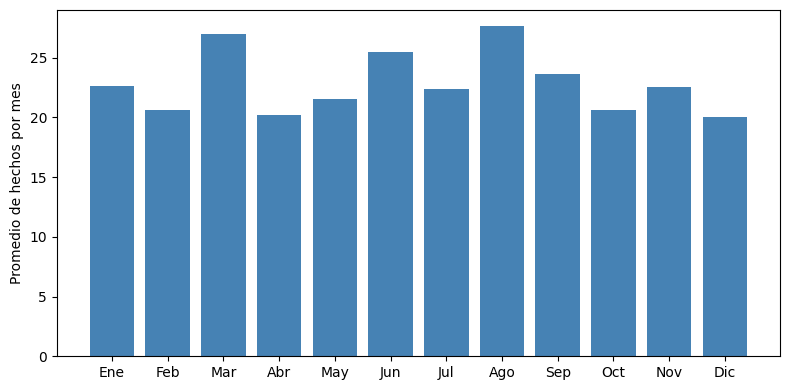

In [14]:
mes_hechos = df_sec['FECHA_HECHO'].dt.month
hechos_mes = df_sec.groupby(mes_hechos)['CANTIDAD'].sum()

meses_periodo = pd.period_range('2010-01', '2026-07', freq='M')
anios_obs = pd.Series(meses_periodo.month).value_counts().sort_index()

prom_mes = (hechos_mes / anios_obs).round(1)
print(pd.DataFrame({'HECHOS': hechos_mes, 'ANIOS_OBS': anios_obs, 'PROMEDIO': prom_mes}))

nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(nombres, prom_mes.values, color='steelblue')
ax.set_ylabel('Promedio de hechos por mes')
plt.tight_layout()
plt.savefig('fig3_estacionalidad.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.5 Capa para los mapas

Construimos una capa con el contorno de cada unidad del MGN y, por cada una, los hechos 2010 – jul. 2026, el área y los hechos por 100 km². Los municipios sin eventos quedan con 0 hechos. La guardamos como GeoPackage para abrirla en ArcGIS.

Los mapas muestran el patrón territorial mucho mejor que una tabla. Unir los datos aquí, y no en ArcGIS, evita errores con el cero inicial de los códigos.

In [15]:
datos_mapa = universo[['COD_MUNI', 'MUNICIPIO', 'DEPARTAMENTO', 'AREA_KM2']].merge(
    por_muni.reset_index().rename(columns={'COD': 'COD_MUNI'})[['COD_MUNI', 'HECHOS']],
    on='COD_MUNI', how='left')
datos_mapa['HECHOS'] = datos_mapa['HECHOS'].fillna(0).astype(int)
datos_mapa['HECHOS_100KM2'] = (datos_mapa['HECHOS'] / datos_mapa['AREA_KM2'] * 100).round(2)

mapa = (gdf[['mpio_cdpmp', 'geometry']]
        .rename(columns={'mpio_cdpmp': 'COD_MUNI'})
        .merge(datos_mapa, on='COD_MUNI', how='left'))

print("Unidades en la capa:", mapa.shape[0])
print("Hechos en total:", mapa['HECHOS'].sum())
print("Unidades sin dato (áreas no municipalizadas):", mapa['HECHOS'].isna().sum())
print("Municipios del universo sin hechos:", (datos_mapa['HECHOS'] == 0).sum())
print("Sistema de coordenadas:", mapa.crs)

mapa.to_file('mapa_hechos_municipio.gpkg', driver='GPKG')

Unidades en la capa: 1122
Hechos en total: 4547.0
Unidades sin dato (áreas no municipalizadas): 18
Municipios del universo sin hechos: 543
Sistema de coordenadas: EPSG:4326


### 2.6 Exportación a shapefile

Guardamos la capa `mapa` en formato shapefile, con nombres de campo cortos y un campo de tipo de unidad.

In [16]:
os.makedirs('mapas_arcgis', exist_ok=True)

mapa_shp = (mapa.rename(columns={'DEPARTAMENTO': 'DEPTO', 'HECHOS_100KM2': 'H_100KM2'})
            .merge(gdf[['mpio_cdpmp', 'mpio_tipo']].rename(
                columns={'mpio_cdpmp': 'COD_MUNI', 'mpio_tipo': 'TIPO'}),
                on='COD_MUNI', how='left'))

print(mapa_shp.shape)
print(mapa_shp.columns.tolist())
print(mapa_shp['TIPO'].value_counts())

mapa_shp.to_file('mapas_arcgis/hechos_municipio.shp', encoding='utf-8')

(1122, 8)
['COD_MUNI', 'geometry', 'MUNICIPIO', 'DEPTO', 'AREA_KM2', 'HECHOS', 'H_100KM2', 'TIPO']
TIPO
MUNICIPIO                 1103
ÁREA NO MUNICIPALIZADA      18
ISLA                         1
Name: count, dtype: int64


### 2.7 Autocorrelación espacial de los hechos (índice I de Moran)

Construimos la matriz de vecindad de los 1.104 municipios, tomando como vecinos los que comparten frontera (contigüidad tipo reina) y estandarizando por filas. Con ella calculamos el índice I de Moran sobre los hechos, sobre log(1 + hechos) y sobre los hechos por 100 km², con 999 permutaciones para el valor p.

El mapa sugiere que los municipios con más hechos se agrupan. El índice de Moran permite comprobarlo con una medida y no solo a simple vista. La misma matriz `w` se usa más adelante, en la sección 10, para revisar los errores del modelo.

In [17]:
mapa_mun = mapa[mapa['HECHOS'].notna()].reset_index(drop=True)   # 1.104 municipios, sin áreas no municipalizadas
mapa_mun['LOG_HECHOS'] = np.log1p(mapa_mun['HECHOS'])

w = weights.Queen.from_dataframe(mapa_mun, use_index=False, silence_warnings=True)
w.transform = 'r'
print("Unidades:", w.n, "| Sin vecinos:", len(w.islands), "| Vecinos promedio:", round(w.mean_neighbors, 1))

np.random.seed(42)
filas = {}
for nombre, col in [('Hechos', 'HECHOS'), ('log(1 + hechos)', 'LOG_HECHOS'),
                    ('Hechos por 100 km²', 'HECHOS_100KM2')]:
    m = Moran(mapa_mun[col].values, w, permutations=999)
    filas[nombre] = {'I de Moran': m.I, 'Esperado': m.EI, 'z': m.z_sim, 'p (permutación)': m.p_sim}

print(pd.DataFrame(filas).T.round(4))

Unidades: 1104 | Sin vecinos: 3 | Vecinos promedio: 5.9
                    I de Moran  Esperado        z  p (permutación)
Hechos                  0.1189   -0.0009   7.0712            0.003
log(1 + hechos)         0.4054   -0.0009  22.6017            0.001
Hechos por 100 km²      0.3825   -0.0009  22.1440            0.001


Los tres municipios sin vecinos quedan por fuera del cálculo del índice:

In [18]:
print(mapa_mun.loc[w.islands, ['COD_MUNI', 'MUNICIPIO', 'DEPARTAMENTO']])

     COD_MUNI    MUNICIPIO                                       DEPARTAMENTO
1087    88001   SAN ANDRÉS  ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANT...
1088    88564  PROVIDENCIA  ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANT...
1099    97666      TARAIRA                                             VAUPÉS


## 3. Panel municipio-mes y variable objetivo

### 3.1 Construcción de la malla

Cruzamos los 1.104 municipios del universo con los 199 meses del periodo (ene. 2010 – jul. 2026) para obtener todas las combinaciones municipio-mes. El resultado se guarda en `malla`.

El archivo de secuestro solo lista eventos. Para que el modelo aprenda también de los casos sin evento (los negativos), necesitamos una fila por cada municipio y cada mes, haya habido hechos o no.

In [19]:
meses = pd.period_range('2010-01', '2026-07', freq='M')

malla = (pd.MultiIndex
         .from_product([universo['COD_MUNI'], meses], names=['COD_MUNI', 'MES'])
         .to_frame(index=False))

print(malla.shape)
print(malla.dtypes)
print(malla.head(3))
print("Municipios:", malla['COD_MUNI'].nunique(), "| Meses:", malla['MES'].nunique())

(219696, 2)
COD_MUNI          str
MES         period[M]
dtype: object
  COD_MUNI      MES
0    05001  2010-01
1    05001  2010-02
2    05001  2010-03
Municipios: 1104 | Meses: 199


### 3.2 Conteo de hechos por municipio y mes

Agrupamos los eventos de `df_sec` por municipio y mes, y calculamos para cada par cuántos registros y cuántos hechos hubo. El resultado se guarda en `conteo`.

Es la información de eventos que vamos a pegar a la malla. Varios registros del mismo municipio y mes se agrupan en una sola fila.

In [20]:
cod_txt = df_sec['COD_MUNI'].astype(int).astype(str).str.zfill(5)

conteo = (df_sec.assign(COD_MUNI=cod_txt, MES=df_sec['FECHA_HECHO'].dt.to_period('M'))
          .groupby(['COD_MUNI', 'MES'])
          .agg(HECHOS=('CANTIDAD', 'sum'), REGISTROS=('CANTIDAD', 'size'))
          .reset_index())

print("Pares municipio-mes con al menos un evento:", conteo.shape[0])
print("Registros:", conteo['REGISTROS'].sum(), "| Hechos:", conteo['HECHOS'].sum())
print(conteo.sort_values('HECHOS', ascending=False).head(5))

Pares municipio-mes con al menos un evento: 2970
Registros: 4384 | Hechos: 4547
     COD_MUNI      MES  HECHOS  REGISTROS
822     19256  2025-09      75         20
746     19050  2025-06      57         16
2960    95025  2025-08      33         11
745     19050  2025-03      29         21
1447    47001  2026-03      25         13


### 3.3 Panel y variable objetivo

Pegamos los conteos a la malla por municipio y mes, rellenamos con 0 donde no hubo eventos y creamos la variable objetivo `y` (1 si hubo al menos un hecho, 0 si no). El resultado se guarda en `panel`.

Así cada municipio-mes, con o sin eventos, queda como una fila con su etiqueta. Los municipio-mes sin evento son los negativos.

In [21]:
panel = malla.merge(conteo, on=['COD_MUNI', 'MES'], how='left')

panel['HECHOS'] = panel['HECHOS'].fillna(0).astype(int)
panel['REGISTROS'] = panel['REGISTROS'].fillna(0).astype(int)
panel['y'] = (panel['HECHOS'] >= 1).astype(int)

print(panel.shape)
print("Hechos:", panel['HECHOS'].sum())
print("Positivos (y=1):", panel['y'].sum())
print("Negativos (y=0):", (panel['y'] == 0).sum())
print(f"Proporción de positivos: {panel['y'].mean():.2%}")

(219696, 5)
Hechos: 4547
Positivos (y=1): 2970
Negativos (y=0): 216726
Proporción de positivos: 1.35%


### 3.4 Guardado del panel base

Guardamos el panel en `panel_base.pkl` para no tener que reconstruirlo cada vez que se abre el cuaderno.

In [22]:
panel.to_pickle('panel_base.pkl')

## 4. Variables (features)

### 4.1 Orden del panel y desplazamiento de un mes

Ordenamos el panel por municipio y mes, y creamos `y_prev`, que contiene el valor de `y` del mes anterior dentro de cada municipio.

Para predecir el mes t solo podemos usar información de meses anteriores. `y_prev` es la forma más simple de esa información, y las demás variables se construyen con la misma idea.

In [23]:
panel = panel.sort_values(['COD_MUNI', 'MES']).reset_index(drop=True)

panel['y_prev'] = panel.groupby('COD_MUNI')['y'].shift(1)

ejemplo = panel[(panel['COD_MUNI'] == '19256') &
                (panel['MES'] >= pd.Period('2025-07', 'M')) &
                (panel['MES'] <= pd.Period('2025-12', 'M'))]
print(ejemplo[['COD_MUNI', 'MES', 'HECHOS', 'y', 'y_prev']])

print("\nFilas con y_prev vacío:", panel['y_prev'].isna().sum())

      COD_MUNI      MES  HECHOS  y  y_prev
74015    19256  2025-07       0  0     0.0
74016    19256  2025-08       0  0     0.0
74017    19256  2025-09      75  1     0.0
74018    19256  2025-10       0  0     1.0
74019    19256  2025-11       0  0     0.0
74020    19256  2025-12       0  0     0.0

Filas con y_prev vacío: 1104


### 4.2 Eventos en los últimos 1, 3, 6 y 12 meses

Para cada municipio-mes contamos cuántos de los 1, 3, 6 y 12 meses anteriores tuvieron al menos un evento. Se guardan como `ev_1m`, `ev_3m`, `ev_6m` y `ev_12m`.

Miden qué tan reciente y persistente es el problema en cada municipio. Se calculan sobre `y_prev`, así que nunca incluyen el mes que se predice.

In [24]:
g = panel.groupby('COD_MUNI')['y_prev']

for k in [1, 3, 6, 12]:
    panel[f'ev_{k}m'] = g.rolling(window=k, min_periods=k).sum().reset_index(level=0, drop=True)

cols_ev = ['ev_1m', 'ev_3m', 'ev_6m', 'ev_12m']
print("Valores vacíos por variable:")
print(panel[cols_ev].isna().sum())

ejemplo = panel[(panel['COD_MUNI'] == '19256') &
                (panel['MES'] >= pd.Period('2025-07', 'M')) &
                (panel['MES'] <= pd.Period('2025-12', 'M'))]
print(ejemplo[['MES', 'y', 'y_prev'] + cols_ev])

Valores vacíos por variable:
ev_1m      1104
ev_3m      3312
ev_6m      6624
ev_12m    13248
dtype: int64
           MES  y  y_prev  ev_1m  ev_3m  ev_6m  ev_12m
74015  2025-07  0     0.0    0.0    0.0    0.0     0.0
74016  2025-08  0     0.0    0.0    0.0    0.0     0.0
74017  2025-09  1     0.0    0.0    0.0    0.0     0.0
74018  2025-10  0     1.0    1.0    1.0    1.0     1.0
74019  2025-11  0     0.0    0.0    1.0    1.0     1.0
74020  2025-12  0     0.0    0.0    1.0    1.0     1.0


### 4.3 Meses desde el último evento

Calculamos, para cada municipio-mes, cuántos meses han pasado desde el último mes con evento anterior a él. Si nunca hubo uno, o hace más de 24 meses, se registra 24.

Mide cuánto tiempo lleva un municipio "en silencio". Un valor bajo indica un evento reciente.

In [25]:
g = panel.groupby('COD_MUNI')

panel['t_idx'] = g.cumcount()
panel['ult_evento'] = panel['t_idx'].where(panel['y'] == 1)
panel['ult_evento'] = panel.groupby('COD_MUNI')['ult_evento'].shift(1)
panel['ult_evento'] = panel.groupby('COD_MUNI')['ult_evento'].ffill()

panel['meses_desde'] = (panel['t_idx'] - panel['ult_evento']).fillna(24).clip(upper=24)

panel = panel.drop(columns=['t_idx', 'ult_evento'])

print("Mínimo:", panel['meses_desde'].min())
print(f"Filas en el tope (24): {(panel['meses_desde'] == 24).mean():.1%}")

ejemplo = panel[(panel['COD_MUNI'] == '19256') &
                (panel['MES'] >= pd.Period('2025-07', 'M')) &
                (panel['MES'] <= pd.Period('2025-12', 'M'))]
print(ejemplo[['MES', 'y', 'ev_1m', 'meses_desde']])

Mínimo: 1.0
Filas en el tope (24): 85.0%
           MES  y  ev_1m  meses_desde
74015  2025-07  0    0.0         24.0
74016  2025-08  0    0.0         24.0
74017  2025-09  1    0.0         24.0
74018  2025-10  0    1.0          1.0
74019  2025-11  0    0.0          2.0
74020  2025-12  0    0.0          3.0


### 4.4 Mes del año y hechos acumulados por área

Agregamos `mes_anio` (1 a 12) y calculamos los hechos acumulados de cada municipio hasta el mes anterior, también expresados por cada 100 km² (`acum_hechos` y `acum_100km2`).

`mes_anio` permite que el modelo capte una posible estacionalidad. El acumulado resume el historial largo de cada municipio, y dividirlo entre el área lo hace comparable entre municipios de tamaños muy distintos.

In [26]:
panel['mes_anio'] = panel['MES'].dt.month

panel['acum_hechos'] = panel.groupby('COD_MUNI')['HECHOS'].cumsum() - panel['HECHOS']

panel = panel.merge(universo[['COD_MUNI', 'AREA_KM2']], on='COD_MUNI', how='left')
panel['acum_100km2'] = panel['acum_hechos'] / panel['AREA_KM2'] * 100

print("mes_anio:", panel['mes_anio'].min(), "a", panel['mes_anio'].max())
print("Filas:", panel.shape[0])

ejemplo = panel[(panel['COD_MUNI'] == '19256') &
                (panel['MES'] >= pd.Period('2025-07', 'M')) &
                (panel['MES'] <= pd.Period('2025-12', 'M'))]
print(ejemplo[['MES', 'HECHOS', 'acum_hechos', 'AREA_KM2', 'acum_100km2', 'mes_anio']].round(2))

mes_anio: 1 a 12
Filas: 219696
           MES  HECHOS  acum_hechos  AREA_KM2  acum_100km2  mes_anio
74015  2025-07       0           15   2741.48         0.55         7
74016  2025-08       0           15   2741.48         0.55         8
74017  2025-09      75           15   2741.48         0.55         9
74018  2025-10       0           90   2741.48         3.28        10
74019  2025-11       0           90   2741.48         3.28        11
74020  2025-12       0           90   2741.48         3.28        12


### 4.5 Verificación de las variables

Comprobamos con tres pruebas que ninguna variable usa información del mes que se predice, y comparamos el promedio de cada variable entre los municipio-mes con evento y sin evento.

Un modelo con fuga de información parece excelente en la validación y falla en el uso real. Y si las variables no se parecen más a los eventos que a los no eventos, el modelo no tendría de qué aprender.

In [27]:
g = panel.groupby('COD_MUNI')

ok1 = (panel.loc[panel['ev_1m'].notna(), 'ev_1m'] == panel.loc[panel['ev_1m'].notna(), 'y_prev']).all()

d = g['acum_hechos'].diff()
h = g['HECHOS'].shift(1)
ok2 = (d.dropna() == h[d.notna()]).all()

ok3 = (panel.loc[panel['y_prev'] == 1, 'meses_desde'] == 1).all()

print("Prueba 1 (ev_1m = mes anterior):", ok1)
print("Prueba 2 (acumulado excluye el mes actual):", ok2)
print("Prueba 3 (tras un evento, meses_desde = 1):", ok3)

cols_x = ['ev_1m', 'ev_3m', 'ev_6m', 'ev_12m', 'meses_desde', 'acum_100km2']
completo = panel.dropna(subset=['ev_12m'])

print("\nFilas con historia completa:", completo.shape[0])
print(completo['y'].value_counts())
print("\nPromedio de cada variable según y:")
print(completo.groupby('y')[cols_x].mean().round(3))

Prueba 1 (ev_1m = mes anterior): True
Prueba 2 (acumulado excluye el mes actual): True
Prueba 3 (tras un evento, meses_desde = 1): True

Filas con historia completa: 206448
y
0    203696
1      2752
Name: count, dtype: int64

Promedio de cada variable según y:
   ev_1m  ev_3m  ev_6m  ev_12m  meses_desde  acum_100km2
y                                                       
0  0.011  0.034  0.068   0.136       21.946        0.462
1  0.164  0.501  0.995   1.941       12.208        3.777


### 4.6 Guardado del panel con variables

Guardamos el panel con las variables en `panel_variables.pkl`.

In [28]:
panel.to_pickle('panel_variables.pkl')

## 5. Partición temporal

### 5.1 Entrenamiento, validación y prueba

Nos quedamos con las filas que tienen historia completa (`datos`) y las dividimos en orden cronológico: entrenamiento (ene. 2011 – dic. 2022), validación (2023) y prueba (ene. 2024 – jul. 2026). Verificamos meses, filas y positivos de cada parte.

El modelo debe predecir el futuro, así que se entrena con el pasado, se valida con lo siguiente y se prueba con lo más reciente. La prueba se crea ahora pero no se usa hasta el final.

In [29]:
datos = panel.dropna(subset=['ev_12m']).copy()

train = datos[datos['MES'] <= pd.Period('2022-12', 'M')]
valid = datos[(datos['MES'] >= pd.Period('2023-01', 'M')) &
              (datos['MES'] <= pd.Period('2023-12', 'M'))]
test = datos[datos['MES'] >= pd.Period('2024-01', 'M')]

partes = {'Entrenamiento': train, 'Validación': valid, 'Prueba': test}

resumen = pd.DataFrame({
    'Desde': [d['MES'].min() for d in partes.values()],
    'Hasta': [d['MES'].max() for d in partes.values()],
    'Meses': [d['MES'].nunique() for d in partes.values()],
    'Filas': [len(d) for d in partes.values()],
    'Positivos': [d['y'].sum() for d in partes.values()],
}, index=partes.keys())
resumen['% positivos'] = (resumen['Positivos'] / resumen['Filas'] * 100).round(2)

print(resumen)
print("\nTotal de filas:", resumen['Filas'].sum(), "| ¿Coincide con datos?", resumen['Filas'].sum() == len(datos))

                 Desde    Hasta  Meses   Filas  Positivos  % positivos
Entrenamiento  2011-01  2022-12    144  158976       1930         1.21
Validación     2023-01  2023-12     12   13248        224         1.69
Prueba         2024-01  2026-07     31   34224        598         1.75

Total de filas: 206448 | ¿Coincide con datos? True


### 5.2 Figura de la partición

Graficamos cuántos municipios tuvieron al menos un evento en cada mes, y sombreamos los tres periodos de la partición.

Muestra de un vistazo cómo se reparte el tiempo entre entrenamiento, validación y prueba, y que el nivel de eventos sube hacia el final.


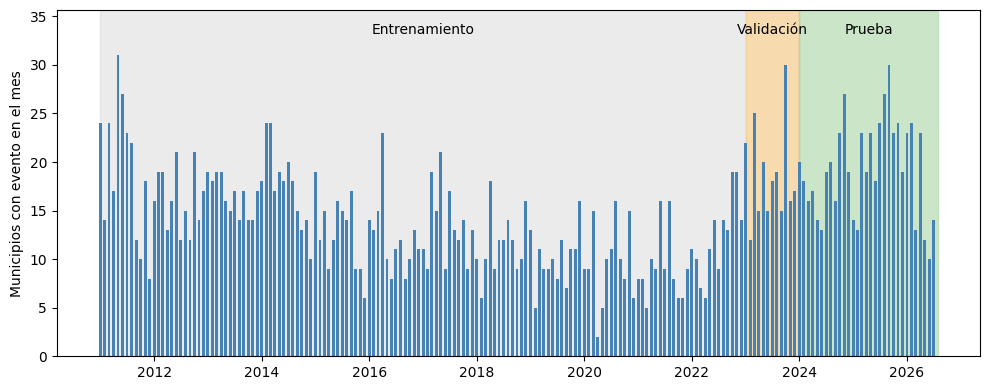

In [30]:
pos_mes = datos.groupby('MES')['y'].sum()
x = pos_mes.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(pd.Timestamp('2011-01-01'), pd.Timestamp('2022-12-31'), color='#d9d9d9', alpha=0.5)
ax.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31'), color='#f4c27a', alpha=0.6)
ax.axvspan(pd.Timestamp('2024-01-01'), pd.Timestamp('2026-07-31'), color='#a8d5a2', alpha=0.6)
ax.bar(x, pos_mes.values, width=20, color='steelblue')

techo = pos_mes.max() * 1.15
ax.set_ylim(0, techo)
ax.text(pd.Timestamp('2016-12-31'), techo * 0.93, 'Entrenamiento', ha='center')
ax.text(pd.Timestamp('2023-07-01'), techo * 0.93, 'Validación', ha='center')
ax.text(pd.Timestamp('2025-04-15'), techo * 0.93, 'Prueba', ha='center')

ax.set_ylabel('Municipios con evento en el mes')
plt.tight_layout()
plt.savefig('fig5_particion.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Modelos de referencia

### 6.1 Puntuaciones de las líneas base

Calculamos, para cada municipio-mes de validación (2023), tres puntuaciones de riesgo: la frecuencia histórica del municipio en el entrenamiento, si el mes anterior tuvo evento y el promedio móvil de 12 meses. Como cuarta referencia se usa el azar.

Son reglas simples que cualquiera podría aplicar. Cada una ordena los municipios de mayor a menor riesgo, y sirven para saber cuánto aporta el modelo frente a ellas.

In [31]:
freq_train = train.groupby('COD_MUNI')['y'].mean().rename('score_freq')

valid_b = valid[['COD_MUNI', 'MES', 'y', 'ev_1m', 'ev_12m']].copy()
valid_b = valid_b.merge(freq_train, on='COD_MUNI', how='left')
valid_b['score_mes_ant'] = valid_b['ev_1m']
valid_b['score_ma12'] = valid_b['ev_12m'] / 12

print(valid_b.shape)
print("Filas sin frecuencia histórica:", valid_b['score_freq'].isna().sum())
print(valid_b[['score_freq', 'score_mes_ant', 'score_ma12']].describe().round(4))

nombres = universo.set_index('COD_MUNI')['MUNICIPIO']
top = freq_train.sort_values(ascending=False).head(5)
print("\nMunicipios con mayor frecuencia histórica:")
print(pd.DataFrame({'MUNICIPIO': nombres[top.index], 'FRECUENCIA': top.round(3)}))
print("\nMunicipios con frecuencia 0 en entrenamiento:", (freq_train == 0).sum())

(13248, 8)
Filas sin frecuencia histórica: 0
       score_freq  score_mes_ant  score_ma12
count  13248.0000     13248.0000  13248.0000
mean       0.0121         0.0167      0.0145
std        0.0404         0.1281      0.0599
min        0.0000         0.0000      0.0000
25%        0.0000         0.0000      0.0000
50%        0.0000         0.0000      0.0000
75%        0.0139         0.0000      0.0000
max        0.7083         1.0000      0.8333

Municipios con mayor frecuencia histórica:
                   MUNICIPIO  FRECUENCIA
COD_MUNI                                
11001           BOGOTÁ, D.C.       0.708
76001       SANTIAGO DE CALI       0.562
05001               MEDELLÍN       0.521
76109           BUENAVENTURA       0.306
54001     SAN JOSÉ DE CÚCUTA       0.306

Municipios con frecuencia 0 en entrenamiento: 615


### 6.2 Evaluación de las líneas base: AUC-ROC y AUC-PR

Calculamos el AUC-ROC y el AUC-PR de cada línea base sobre la validación, y los comparamos con el azar.

Son métricas de ranking que no dependen de elegir un umbral y que sirven con clases muy desbalanceadas.

In [32]:
scores = {'Frecuencia histórica': 'score_freq',
          'Mes anterior': 'score_mes_ant',
          'Media móvil 12 meses': 'score_ma12'}

res = pd.DataFrame({
    nombre: {'AUC-ROC': roc_auc_score(valid_b['y'], valid_b[col]),
             'AUC-PR': average_precision_score(valid_b['y'], valid_b[col])}
    for nombre, col in scores.items()
}).T.round(3)

print(res)
print("\nAUC-PR del azar (proporción de positivos):", round(valid_b['y'].mean(), 4))

sin_hist = (valid_b.loc[valid_b['y'] == 1, 'score_freq'] == 0).mean()
print(f"Positivos de validación en municipios sin eventos en el entrenamiento: {sin_hist:.1%}")

                      AUC-ROC  AUC-PR
Frecuencia histórica    0.843   0.243
Mes anterior            0.587   0.049
Media móvil 12 meses    0.776   0.213

AUC-PR del azar (proporción de positivos): 0.0169
Positivos de validación en municipios sin eventos en el entrenamiento: 10.3%


### 6.3 Evaluación de las líneas base: captura en el top-k

Para cada mes de validación ordenamos los 1.104 municipios por cada puntuación, tomamos los k primeros (25, 50 y 100) y calculamos qué fracción de los municipios con evento de ese mes estaba en esa lista. Promediamos los 12 meses.

Es la métrica más cercana al uso real: un equipo de seguridad solo puede atender un número limitado de municipios por mes.

In [33]:
rng = np.random.default_rng(42)
valid_b['azar'] = rng.random(len(valid_b))

def captura_topk(df, col, k):
    capturas = []
    for mes, d in df.groupby('MES'):
        positivos = d['y'].sum()
        if positivos == 0:
            continue
        top = d.sort_values([col, 'azar'], ascending=[False, False]).head(k)
        capturas.append(top['y'].sum() / positivos)
    return np.mean(capturas)

ks = [25, 50, 100]
tabla_k = pd.DataFrame({
    nombre: {f'Top-{k}': captura_topk(valid_b, col, k) for k in ks}
    for nombre, col in scores.items()
}).T
tabla_k = (tabla_k * 100).round(1)

print(tabla_k)
print("\nAzar:", {f'Top-{k}': round(k / len(universo) * 100, 1) for k in ks})

                      Top-25  Top-50  Top-100
Frecuencia histórica    38.6    48.5     58.0
Mes anterior            21.1    25.2     29.9
Media móvil 12 meses    37.4    44.8     58.1

Azar: {'Top-25': 2.3, 'Top-50': 4.5, 'Top-100': 9.1}


## 7. Regresión logística

### 7.1 Nueva variable: frecuencia histórica (`frec_hist`)

En los modelos de referencia (6.3), la frecuencia histórica por municipio fue la mejor línea base. Nuestras variables solo miran ventanas de 1 a 12 meses y no incluyen esa información, así que agregamos `frec_hist`.

**Definición:** proporción de meses con al menos un evento en el municipio, desde el inicio de la serie hasta el mes anterior (t−1).

**Control de fuga:** al `cumsum` de `y` se le resta el `y` del mes actual y se divide por los meses previos (`cumcount`). El primer mes de cada municipio queda en NaN.

**Verificación:** 3 pruebas (primer mes NaN, recálculo manual en un municipio, rango entre 0 y 1) y comparación del promedio según `y`.

In [34]:
# 7.1 frec_hist: proporción de meses con evento hasta t-1
g = panel.groupby('COD_MUNI')
panel['frec_hist'] = (g['y'].cumsum() - panel['y']) / g.cumcount()

# Prueba 1: el primer mes de cada municipio no tiene historia (NaN)
primer = panel.groupby('COD_MUNI').head(1)
print('Prueba 1 (primer mes = NaN):', primer['frec_hist'].isna().all())

# Prueba 2: recálculo manual en el municipio con más meses con evento
cod = panel.groupby('COD_MUNI')['y'].sum().idxmax()
nombre = universo.loc[universo['COD_MUNI']==cod, 'MUNICIPIO'].iloc[0]
m = panel[panel['COD_MUNI']==cod].reset_index(drop=True)
manual = [np.nan] + [m['y'].iloc[:i].mean() for i in range(1, len(m))]
ok2 = np.allclose(m['frec_hist'].fillna(-1), pd.Series(manual).fillna(-1))
print(f'Prueba 2 (manual en {nombre}, {cod}):', ok2)

# Prueba 3: valores entre 0 y 1
print('Prueba 3 (rango 0-1):', panel['frec_hist'].dropna().between(0, 1).all())

# Descriptivo: promedio de frec_hist según y (filas con historia completa)
base = panel.dropna(subset=['ev_12m'])
print(base.groupby('y')['frec_hist'].mean().round(4))
print(m[['MES','y','frec_hist']].tail(3))

Prueba 1 (primer mes = NaN): True
Prueba 2 (manual en BOGOTÁ, D.C., 11001): True
Prueba 3 (rango 0-1): True
y
0    0.0125
1    0.1530
Name: frec_hist, dtype: float64
         MES  y  frec_hist
196  2026-05  1   0.704082
197  2026-06  0   0.705584
198  2026-07  1   0.702020


**Resultado 7.1.** Las tres pruebas de fuga dieron `True`. El promedio de `frec_hist` es 0,153 cuando hubo evento (y=1) y 0,0125 cuando no (y=0), unas 12 veces mayor, igual que lo observado con las variables `ev_*`. Esto es un resultado descriptivo, no causal: los municipios que ya han tenido eventos con frecuencia son los que más los vuelven a tener. Ejemplo: Bogotá ha tenido evento en cerca del 70 % de sus meses previos.

### 7.2 Partición temporal con `frec_hist`

Volvemos a construir `datos`, `train`, `valid` y `test` desde `panel`, que ya incluye `frec_hist`, con los mismos cortes de 5.1 (entrenamiento 2011 a 2022, validación 2023 y prueba desde 2024).

Las copias anteriores se hicieron antes de crear la variable y no la tienen.

In [35]:
datos = panel.dropna(subset=['ev_12m']).copy()

train = datos[datos['MES'] <= pd.Period('2022-12', 'M')]
valid = datos[(datos['MES'] >= pd.Period('2023-01', 'M')) & (datos['MES'] <= pd.Period('2023-12', 'M'))]
test  = datos[datos['MES'] >= pd.Period('2024-01', 'M')]

for nombre, d in [('train', train), ('valid', valid), ('test', test)]:
    print(f"{nombre}: {len(d):,} filas | positivos: {d['y'].sum():,} | frec_hist vacíos: {d['frec_hist'].isna().sum()}")
print("Total:", f"{len(datos):,}")

train: 158,976 filas | positivos: 1,930 | frec_hist vacíos: 0
valid: 13,248 filas | positivos: 224 | frec_hist vacíos: 0
test: 34,224 filas | positivos: 598 | frec_hist vacíos: 0
Total: 206,448


### 7.3 Preparación de las variables

Armamos la matriz de entrada del modelo. Las 7 variables numéricas (`ev_1m`, `ev_3m`, `ev_6m`, `ev_12m`, `meses_desde`, `acum_100km2`, `frec_hist`) se estandarizan, y `mes_anio` se convierte en 11 columnas de 0/1 (enero es la referencia). A `acum_100km2` se le aplica antes `log(1 + x)` porque tiene unas pocas ciudades con valores muy altos.

La estandarización deja los coeficientes comparables y ayuda a que el modelo converja. El mes del año es una categoría, no una cantidad, así que se codifica en columnas separadas. La media y la desviación estándar se calculan **solo con train** para no filtrar información de validación.

In [36]:
num_cols = ['ev_1m', 'ev_3m', 'ev_6m', 'ev_12m', 'meses_desde', 'acum_100km2', 'frec_hist']

def base_X(d):
    X = d[num_cols].copy()
    X['acum_100km2'] = np.log1p(X['acum_100km2'])
    return X

def dummies_mes(d):
    cat = d['mes_anio'].astype(pd.CategoricalDtype(range(1, 13)))
    return pd.get_dummies(cat, prefix='mes', drop_first=True).astype(int)

scaler = StandardScaler().fit(base_X(train))   # se ajusta SOLO con train

def armar(d):
    num = pd.DataFrame(scaler.transform(base_X(d)), columns=num_cols, index=d.index)
    return pd.concat([num, dummies_mes(d)], axis=1)

X_train, X_valid = armar(train), armar(valid)
y_train, y_valid = train['y'], valid['y']

print(X_train.shape, X_valid.shape)
print(X_train.columns.tolist())
print("Vacíos:", X_train.isna().sum().sum(), X_valid.isna().sum().sum())
print("\nTrain (media y desviación):")
print(X_train[num_cols].agg(['mean', 'std']).round(3))
print("\nValidación (media y desviación):")
print(X_valid[num_cols].agg(['mean', 'std']).round(3))

(158976, 18) (13248, 18)
['ev_1m', 'ev_3m', 'ev_6m', 'ev_12m', 'meses_desde', 'acum_100km2', 'frec_hist', 'mes_2', 'mes_3', 'mes_4', 'mes_5', 'mes_6', 'mes_7', 'mes_8', 'mes_9', 'mes_10', 'mes_11', 'mes_12']
Vacíos: 0 0

Train (media y desviación):
      ev_1m  ev_3m  ev_6m  ev_12m  meses_desde  acum_100km2  frec_hist
mean   -0.0   -0.0   -0.0    -0.0          0.0         -0.0        0.0
std     1.0    1.0    1.0     1.0          1.0          1.0        1.0

Validación (media y desviación):
      ev_1m  ev_3m  ev_6m  ev_12m  meses_desde  acum_100km2  frec_hist
mean  0.041  0.061  0.064   0.041       -0.002        0.271     -0.045
std   1.170  1.194  1.208   1.170        1.049        1.290      0.865


### 7.4 Entrenamiento del modelo

Ajustamos una regresión logística con las 18 columnas de `X_train`, usando solo los datos de train. Se aplican pesos de clase balanceados para que los eventos, que son solo el 1,2 % de las filas, pesen más en el ajuste.

Sin pesos, el modelo puede "ganar" prediciendo casi siempre 0. Con pesos, aprende a distinguir los municipio-mes de mayor riesgo. El modelo usa regularización L2 (opción por defecto de `scikit-learn`), que evita coeficientes exagerados.

In [37]:
modelo = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)

n = len(y_train)
n1 = int(y_train.sum())
n0 = n - n1
print("Iteraciones usadas:", modelo.n_iter_[0], "(máximo 1000)")
print("Intercepto:", modelo.intercept_.round(3))
print("Número de coeficientes:", modelo.coef_.shape[1])
print(f"Peso clase 0: {n/(2*n0):.3f} | Peso clase 1: {n/(2*n1):.2f} | Razón: {n0/n1:.1f}")

Iteraciones usadas: 24 (máximo 1000)
Intercepto: [-0.641]
Número de coeficientes: 18
Peso clase 0: 0.506 | Peso clase 1: 41.19 | Razón: 81.4


### 7.5 Evaluación en validación

Calculamos la probabilidad que da el modelo a cada municipio-mes de 2023 y la evaluamos con las mismas métricas de 6.2 y 6.3 (AUC-ROC, AUC-PR y captura en el top 25, 50 y 100), junto a las líneas base.

Queremos saber si la regresión logística mejora a la mejor línea base, la frecuencia histórica (AUC-ROC 0,843, AUC-PR 0,243 y top-50 de 48,5 %). Se usa la validación y el conjunto de prueba sigue sin tocarse.

In [38]:
# Comprobar que valid_b y valid tienen el mismo orden de filas
assert (valid_b['COD_MUNI'].values == valid['COD_MUNI'].values).all()
assert (valid_b['MES'].values == valid['MES'].values).all()

valid_b['score_logit'] = modelo.predict_proba(X_valid)[:, 1]

scores_all = {**scores, 'Regresión logística': 'score_logit'}

res = pd.DataFrame({
    nombre: {'AUC-ROC': roc_auc_score(valid_b['y'], valid_b[col]),
             'AUC-PR': average_precision_score(valid_b['y'], valid_b[col])}
    for nombre, col in scores_all.items()
}).T.round(3)

tk = pd.DataFrame({
    nombre: {f'Top-{k}': captura_topk(valid_b, col, k) for k in ks}
    for nombre, col in scores_all.items()
}).T
tk = (tk * 100).round(1)

print(res.join(tk).sort_values('AUC-ROC', ascending=False))

                      AUC-ROC  AUC-PR  Top-25  Top-50  Top-100
Regresión logística     0.850   0.255    36.5    47.3     60.9
Frecuencia histórica    0.843   0.243    38.6    48.5     58.0
Media móvil 12 meses    0.776   0.213    37.4    44.8     58.1
Mes anterior            0.587   0.049    21.1    25.2     29.9


### 7.6 Coeficientes y odds ratios

Mostramos el coeficiente de cada variable y su odds ratio (e elevado al coeficiente), ordenados por tamaño.

Buscamos entender qué variables usa el modelo y en qué sentido. Como las variables numéricas están estandarizadas, cada coeficiente se lee por **un aumento de una desviación estándar**. En los meses, el coeficiente se lee frente a enero.

In [39]:
coefs = pd.DataFrame({'variable': X_train.columns, 'coef': modelo.coef_[0]})
coefs['odds_ratio'] = np.exp(coefs['coef'])

orden = coefs['coef'].abs().sort_values(ascending=False).index
print(coefs.loc[orden].round(3).to_string(index=False))

   variable   coef  odds_ratio
  frec_hist  0.771       2.162
meses_desde -0.370       0.691
      mes_3  0.189       1.208
     mes_12 -0.172       0.842
      mes_9 -0.168       0.846
     ev_12m -0.146       0.865
      mes_8  0.142       1.152
      mes_4  0.127       1.136
      mes_7  0.122       1.129
acum_100km2  0.120       1.127
      mes_6  0.068       1.070
      mes_2 -0.065       0.937
      mes_5  0.064       1.066
      ev_6m -0.051       0.950
     mes_10 -0.042       0.958
     mes_11  0.029       1.029
      ev_3m -0.028       0.972
      ev_1m  0.007       1.007


## 8. Modelo de ensamble: bosque aleatorio

### 8.1 Variables e hiperparámetros

Armamos la entrada del bosque aleatorio con las 7 variables numéricas y `mes_anio` como número, sin estandarizar ni transformar, y dejamos fijos los hiperparámetros: 300 árboles, profundidad máxima 8, mínimo 50 filas por hoja y pesos de clase balanceados (los mismos de la logística).

Los árboles preguntan por umbrales y no necesitan escalar las variables. Los hiperparámetros se fijan antes de ver la validación, para no ajustar el modelo a ella. En 8.5 se confirman con una validación cruzada de origen móvil dentro del entrenamiento.

**Regla de decisión (fijada antes de evaluar):** el ensamble reemplaza a la regresión logística como modelo final solo si mejora el AUC-PR en al menos 0,03 y la captura top-50 en al menos 3 puntos porcentuales (frente a 0,255 y 47,3 %). En caso contrario, la logística sigue como modelo final.

In [40]:
cols_rf = ['ev_1m', 'ev_3m', 'ev_6m', 'ev_12m', 'meses_desde',
           'acum_100km2', 'frec_hist', 'mes_anio']

X_train_rf = train[cols_rf]
X_valid_rf = valid[cols_rf]

params_rf = dict(n_estimators=300, max_depth=8, min_samples_leaf=50,
                 class_weight='balanced', n_jobs=-1, random_state=42)

print(X_train_rf.shape, X_valid_rf.shape)
print("Vacíos:", X_train_rf.isna().sum().sum(), X_valid_rf.isna().sum().sum())
print(X_train_rf.describe().round(3).T[['min', 'mean', 'max']])
print(params_rf)

(158976, 8) (13248, 8)
Vacíos: 0 0
             min    mean     max
ev_1m        0.0   0.012   1.000
ev_3m        0.0   0.037   3.000
ev_6m        0.0   0.073   6.000
ev_12m       0.0   0.148  12.000
meses_desde  1.0  21.906  24.000
acum_100km2  0.0   0.406  44.694
frec_hist    0.0   0.015   0.840
mes_anio     1.0   6.500  12.000
{'n_estimators': 300, 'max_depth': 8, 'min_samples_leaf': 50, 'class_weight': 'balanced', 'n_jobs': -1, 'random_state': 42}


### 8.2 Entrenamiento del bosque aleatorio

Entrenamos el bosque con los hiperparámetros fijados en 8.1, usando solo los datos de train.

Es el segundo modelo de la comparación del objetivo 3. Se entrena una sola vez y no se ajusta mirando la validación.

In [41]:
t0 = time.time()
rf = RandomForestClassifier(**params_rf)
rf.fit(X_train_rf, y_train)
print(f"Entrenado en {time.time() - t0:.1f} s")

print("Árboles:", len(rf.estimators_))
print("Profundidad máxima real:", max(e.get_depth() for e in rf.estimators_))
print("Hojas promedio por árbol:", round(np.mean([e.get_n_leaves() for e in rf.estimators_]), 1))

p_train = rf.predict_proba(X_train_rf)[:, 1]
print("Probabilidad promedio en train:", round(p_train.mean() * 100, 2), "%")

Entrenado en 4.3 s
Árboles: 300
Profundidad máxima real: 8
Hojas promedio por árbol: 98.1
Probabilidad promedio en train: 32.7 %


### 8.3 Evaluación en validación y regla de decisión

Calculamos la probabilidad que da el bosque a cada municipio-mes de 2023 y la evaluamos con las mismas métricas de 6.2, 6.3 y 7.5 (AUC-ROC, AUC-PR y captura top-25, 50 y 100), junto con la regresión logística y las líneas base. Después aplicamos la regla de decisión fijada en 8.1.

Buscamos saber si el ensamble mejora a la regresión logística lo suficiente como para reemplazarla.

In [42]:
# Comprobar que el orden de filas coincide con valid_b
assert (valid_b['COD_MUNI'].values == valid['COD_MUNI'].values).all()
assert (valid_b['MES'].values == valid['MES'].values).all()

valid_b['score_rf'] = rf.predict_proba(X_valid_rf)[:, 1]

scores_2 = {**scores_all, 'Bosque aleatorio': 'score_rf'}

res2 = pd.DataFrame({
    n: {'AUC-ROC': roc_auc_score(valid_b['y'], valid_b[c]),
        'AUC-PR': average_precision_score(valid_b['y'], valid_b[c])}
    for n, c in scores_2.items()}).T
tk2 = pd.DataFrame({
    n: {f'Top-{k}': captura_topk(valid_b, c, k) * 100 for k in ks}
    for n, c in scores_2.items()}).T

print(res2.round(3).join(tk2.round(1)).sort_values('AUC-ROC', ascending=False))

d_pr = res2.loc['Bosque aleatorio', 'AUC-PR'] - res2.loc['Regresión logística', 'AUC-PR']
d_k50 = tk2.loc['Bosque aleatorio', 'Top-50'] - tk2.loc['Regresión logística', 'Top-50']
print(f"\nDiferencia AUC-PR (bosque − logística): {d_pr:+.3f} (umbral: +0,030)")
print(f"Diferencia top-50 (bosque − logística): {d_k50:+.1f} puntos (umbral: +3,0)")
print("El bosque reemplaza a la logística:", bool(d_pr >= 0.03 and d_k50 >= 3.0))

                      AUC-ROC  AUC-PR  Top-25  Top-50  Top-100
Regresión logística     0.850   0.255    36.5    47.3     60.9
Bosque aleatorio        0.848   0.273    38.2    48.6     59.7
Frecuencia histórica    0.843   0.243    38.6    48.5     58.0
Media móvil 12 meses    0.776   0.213    37.4    44.8     58.1
Mes anterior            0.587   0.049    21.1    25.2     29.9

Diferencia AUC-PR (bosque − logística): +0.018 (umbral: +0,030)
Diferencia top-50 (bosque − logística): +1.2 puntos (umbral: +3,0)
El bosque reemplaza a la logística: False


### 8.4 Importancia de las variables

Medimos qué variables usa el bosque de dos maneras: la importancia por impureza (cuánto reduce cada variable el desorden de los grupos, calculada en train) y la importancia por permutación (cuánto cae el AUC-PR en validación al desordenar al azar una variable).

El bosque no da coeficientes. Esto permite comparar con la regresión logística qué variables pesan más.

In [43]:
perm = permutation_importance(rf, X_valid_rf, y_valid, scoring='average_precision',
                              n_repeats=10, random_state=42, n_jobs=-1)

imp = pd.DataFrame({'variable': cols_rf,
                    'importancia_gini': rf.feature_importances_,
                    'caida_AUC_PR': perm.importances_mean,
                    'desv_caida': perm.importances_std})
imp = imp.sort_values('caida_AUC_PR', ascending=False)
print(imp.round(4).to_string(index=False))

   variable  importancia_gini  caida_AUC_PR  desv_caida
  frec_hist            0.3456        0.1760      0.0085
acum_100km2            0.1839        0.0421      0.0170
     ev_12m            0.1431        0.0280      0.0110
meses_desde            0.1832        0.0258      0.0095
      ev_6m            0.0808        0.0112      0.0058
   mes_anio            0.0136        0.0055      0.0031
      ev_3m            0.0423        0.0053      0.0036
      ev_1m            0.0075        0.0034      0.0006


### 8.5 Ajuste de hiperparámetros con validación cruzada de origen móvil

Comparamos 12 combinaciones de profundidad máxima (4, 6, 8 y 12) y mínimo de filas por hoja (20, 50 y 100). Cada combinación se entrena con los años anteriores a uno y se prueba en ese año, para 2019, 2020, 2021 y 2022, y se promedia el AUC-PR de las cuatro rondas. Durante la búsqueda se usan 200 árboles.

Todo ocurre dentro del entrenamiento, así que la búsqueda no usa ni la validación de 2023 ni la prueba. Si la mejor combinación coincide con la de 8.1, el bosque entrenado en 8.2 no cambia.

In [44]:
anios_cv = [2019, 2020, 2021, 2022]
cuadricula = list(product([4, 6, 8, 12], [20, 50, 100]))   # (max_depth, min_samples_leaf)
anio_train = train['MES'].dt.year

resultados_cv = []
t0 = time.time()
for depth, leaf in cuadricula:
    aps = []
    for a in anios_cv:
        tr = train[anio_train < a]
        va = train[anio_train == a]
        m = RandomForestClassifier(n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
                                   class_weight='balanced', n_jobs=-1, random_state=42)
        m.fit(tr[cols_rf], tr['y'])
        aps.append(average_precision_score(va['y'], m.predict_proba(va[cols_rf])[:, 1]))
    resultados_cv.append({'max_depth': depth, 'min_samples_leaf': leaf,
                          'AUC-PR medio': np.mean(aps), 'desv. entre años': np.std(aps)})
    print(f"profundidad {depth}, hoja {leaf}: AUC-PR medio {np.mean(aps):.3f} ({time.time() - t0:.0f} s)")

tabla_cv = pd.DataFrame(resultados_cv).sort_values('AUC-PR medio', ascending=False)
print("\n", tabla_cv.round(4).to_string(index=False))

profundidad 4, hoja 20: AUC-PR medio 0.210 (10 s)
profundidad 4, hoja 50: AUC-PR medio 0.212 (21 s)
profundidad 4, hoja 100: AUC-PR medio 0.211 (32 s)
profundidad 6, hoja 20: AUC-PR medio 0.217 (43 s)
profundidad 6, hoja 50: AUC-PR medio 0.216 (53 s)
profundidad 6, hoja 100: AUC-PR medio 0.215 (63 s)
profundidad 8, hoja 20: AUC-PR medio 0.214 (73 s)
profundidad 8, hoja 50: AUC-PR medio 0.218 (84 s)
profundidad 8, hoja 100: AUC-PR medio 0.215 (95 s)
profundidad 12, hoja 20: AUC-PR medio 0.214 (106 s)
profundidad 12, hoja 50: AUC-PR medio 0.217 (116 s)
profundidad 12, hoja 100: AUC-PR medio 0.215 (126 s)

  max_depth  min_samples_leaf  AUC-PR medio  desv. entre años
         8                50        0.2182            0.0335
        12                50        0.2172            0.0342
         6                20        0.2172            0.0334
         6                50        0.2160            0.0324
         8               100        0.2152            0.0310
         6            

## 9. Calibración y niveles de riesgo

### 9.1 Corrección de las probabilidades y verificación de la calibración

Corregimos las probabilidades del modelo restando ln(81,4) al puntaje (logit), para deshacer el efecto de los pesos de clase. Después comparamos, por tramos de riesgo en validación, la probabilidad promedio predicha con la frecuencia de eventos observada.

Los pesos inflan las probabilidades (un municipio-mes típico recibía 34,5 %). La corrección usa solo datos de entrenamiento, así que la validación sirve como comprobación independiente. La corrección no cambia el orden de los municipios.

In [45]:
# Razón entre pesos de clase (81,4), calculada con train
razon = (len(y_train) - y_train.sum()) / y_train.sum()

# Puntaje (logit) del modelo en validación, corrección y probabilidad calibrada
logit_modelo = modelo.decision_function(X_valid)
valid_b['p_cal'] = 1 / (1 + np.exp(-(logit_modelo - np.log(razon))))

# El orden no cambia: el AUC debe ser el mismo de 7.5
print("AUC-ROC con p_cal:", round(roc_auc_score(valid_b['y'], valid_b['p_cal']), 3))

# Tabla de calibración por tramos de probabilidad
valid_b['grupo'] = pd.qcut(valid_b['p_cal'], q=[0, .5, .8, .9, .95, .99, 1.0], duplicates='drop')
cal = valid_b.groupby('grupo', observed=True).agg(
    filas=('y', 'size'), eventos=('y', 'sum'),
    predicho=('p_cal', 'mean'), observado=('y', 'mean'))
cal['razon_obs_pred'] = (cal['observado'] / cal['predicho']).round(2)
cal[['predicho', 'observado']] = (cal[['predicho', 'observado']] * 100).round(2)
print(cal)

print(f"\nGlobal: predicho: {valid_b['p_cal'].mean()*100:.2f} % | observado: {valid_b['y'].mean()*100:.2f} %")

AUC-ROC con p_cal: 0.85
                    filas  eventos  predicho  observado  razon_obs_pred
grupo                                                                  
(0.0027, 0.00506]    7069       24      0.45       0.34            0.76
(0.00506, 0.00784]   3529       30      0.60       0.85            1.41
(0.00784, 0.0143]    1325       31      1.04       2.34            2.25
(0.0143, 0.0237]      662       27      1.79       4.08            2.28
(0.0237, 0.126]       530       60      4.70      11.32            2.41
(0.126, 0.995]        133       52     45.98      39.10            0.85

Global: predicho: 1.24 % | observado: 1.69 %


### 9.2 Calidad de las probabilidades: Brier y log-loss

Medimos el puntaje de Brier y la pérdida logarítmica (log-loss) de cada opción en validación, y los comparamos con una referencia que asigna a todos los municipio-mes la tasa base del entrenamiento (1,21 %). La columna `BSS vs tasa base` indica cuánto error se reduce frente a esa referencia: 0 es igual, un valor positivo es mejor y uno negativo es peor.

La calibración por tramos muestra la forma del error y estas dos medidas lo resumen en un solo número. A la frecuencia histórica se le acotan los valores entre 0,1 % y 99,9 % para evitar un log-loss infinito. En el bosque, la corrección por pesos de clase es aproximada.

In [46]:
y_v = valid_b['y']
razon = (len(y_train) - y_train.sum()) / y_train.sum()

def corregir(p):
    # quita el efecto de los pesos de clase sobre la probabilidad
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return 1 / (1 + np.exp(-(np.log(p / (1 - p)) - np.log(razon))))

candidatos = {
    'Tasa base constante': np.full(len(y_v), y_train.mean()),
    'Frecuencia histórica': valid_b['score_freq'].clip(0.001, 0.999),
    'Logística sin corregir': valid_b['score_logit'],
    'Logística corregida': valid_b['p_cal'],
    'Bosque corregido (aprox.)': corregir(valid_b['score_rf']),
}

ref = brier_score_loss(y_v, candidatos['Tasa base constante'])
filas = {}
for nombre, p in candidatos.items():
    b = brier_score_loss(y_v, p)
    filas[nombre] = {'Brier': b, 'Log-loss': log_loss(y_v, p), 'BSS vs tasa base': 1 - b / ref}

print(pd.DataFrame(filas).T.round(4))

                            Brier  Log-loss  BSS vs tasa base
Tasa base constante        0.0166    0.0866            0.0000
Frecuencia histórica       0.0143    0.0661            0.1390
Logística sin corregir     0.1347    0.4621           -7.0908
Logística corregida        0.0147    0.0691            0.1162
Bosque corregido (aprox.)  0.0144    0.0662            0.1364


### 9.3 Niveles de riesgo

Definimos dos umbrales sobre la probabilidad calibrada para obtener tres niveles: **Alto** (equivalente a unos 25 municipios por mes), **Medio** (hasta unos 100) y **Bajo** (el resto). Luego medimos, para cada nivel, cuántos municipio-mes contiene, cuántos eventos y qué proporción de los municipios del nivel tuvo evento (precisión).

Un equipo de seguridad atiende un número limitado de municipios. Los umbrales se eligen en validación y no en prueba, y se fijan **una sola vez** para todos los meses.

In [47]:
n_muni = valid_b['COD_MUNI'].nunique()
n_meses = valid_b['MES'].nunique()

u_alto  = valid_b['p_cal'].quantile(1 - 25 / n_muni)
u_medio = valid_b['p_cal'].quantile(1 - 100 / n_muni)
print(f"Umbral Alto: {u_alto:.4f} | Umbral Medio: {u_medio:.4f}")

valid_b['nivel'] = np.where(valid_b['p_cal'] >= u_alto, 'Alto',
                   np.where(valid_b['p_cal'] >= u_medio, 'Medio', 'Bajo'))

tasa_base = valid_b['y'].mean() * 100
res_niv = valid_b.groupby('nivel').agg(filas=('y', 'size'), eventos=('y', 'sum'))
res_niv['municipios_por_mes'] = (res_niv['filas'] / n_meses).round(1)
res_niv['precision_%'] = (res_niv['eventos'] / res_niv['filas'] * 100).round(2)
res_niv['captura_%'] = (res_niv['eventos'] / valid_b['y'].sum() * 100).round(1)
res_niv['veces_tasa_base'] = (res_niv['precision_%'] / tasa_base).round(1)
print(res_niv.loc[['Alto', 'Medio', 'Bajo']])

por_mes = valid_b.groupby(['MES', 'nivel']).size().unstack(fill_value=0)
print("\nMunicipios en nivel Alto por mes (mín, máx):", por_mes['Alto'].min(), por_mes['Alto'].max())

Umbral Alto: 0.0480 | Umbral Medio: 0.0153
       filas  eventos  municipios_por_mes  precision_%  captura_%  \
nivel                                                               
Alto     300       80                25.0        26.67       35.7   
Medio    900       57                75.0         6.33       25.4   
Bajo   12048       87              1004.0         0.72       38.8   

       veces_tasa_base  
nivel                   
Alto              15.8  
Medio              3.7  
Bajo               0.4  

Municipios en nivel Alto por mes (mín, máx): 19 30


### 9.4 Lista priorizada de un mes de validación

Tomamos diciembre de 2023, el último mes de validación, y ordenamos los 1.104 municipios por probabilidad calibrada. Mostramos los 25 primeros, cuántos eventos reales cayeron en cada nivel y los eventos que quedaron en el nivel Bajo.

Es el producto que vería un equipo de seguridad. Mirar un mes concreto nos deja revisar casos reales, aciertos y omisiones, y es la base del mapa de riesgo.

In [48]:
mes_mapa = pd.Period('2023-12', 'M')
dic = valid_b[valid_b['MES'] == mes_mapa].copy()
dic = dic.merge(universo[['COD_MUNI', 'MUNICIPIO', 'DEPARTAMENTO']], on='COD_MUNI', how='left')
dic['p_cal_%'] = (dic['p_cal'] * 100).round(1)
dic = dic.sort_values('p_cal', ascending=False).reset_index(drop=True)
dic['ranking'] = dic.index + 1

print("Eventos del mes:", dic['y'].sum())
print(dic.groupby('nivel')['y'].agg(municipios='size', eventos='sum').loc[['Alto', 'Medio', 'Bajo']])

print("\nLos 25 municipios de mayor riesgo:")
print(dic[['ranking', 'MUNICIPIO', 'DEPARTAMENTO', 'p_cal_%', 'nivel', 'y']].head(25).to_string(index=False))

print("\nEventos del mes en nivel Bajo:")
print(dic.loc[(dic['y'] == 1) & (dic['nivel'] == 'Bajo'), ['MUNICIPIO', 'DEPARTAMENTO', 'p_cal_%']].to_string(index=False))

Eventos del mes: 17
       municipios  eventos
nivel                     
Alto           19        3
Medio          63        5
Bajo         1022        9

Los 25 municipios de mayor riesgo:
 ranking              MUNICIPIO       DEPARTAMENTO  p_cal_% nivel  y
       1           BOGOTÁ, D.C.       BOGOTÁ, D.C.     99.4  Alto  0
       2       SANTIAGO DE CALI    VALLE DEL CAUCA     97.1  Alto  1
       3               MEDELLÍN          ANTIOQUIA     95.5  Alto  1
       4           BUENAVENTURA    VALLE DEL CAUCA     38.7  Alto  0
       5     SAN JOSÉ DE CÚCUTA NORTE DE SANTANDER     37.1  Alto  0
       6                 ARAUCA             ARAUCA     26.3  Alto  0
       7                   TAME             ARAUCA     24.7  Alto  0
       8               SARAVENA             ARAUCA     18.2  Alto  1
       9                POPAYÁN              CAUCA     12.9  Alto  0
      10           BARRANQUILLA          ATLÁNTICO     12.1  Alto  0
      11          VILLAVICENCIO               META

### 9.5 Capa de riesgo para el mapa (diciembre de 2023)

Unimos el nivel de riesgo, la probabilidad y el evento real de diciembre de 2023 con la geometría de las 1.122 unidades del MGN. Las 18 áreas no municipalizadas, que no están en el universo del modelo, quedan marcadas como "Sin dato".

Una primera versión con solo los 1.104 municipios dejó vacíos en el mapa (por ejemplo, en la Amazonía). La capa debe cubrir todo el territorio.

In [49]:
# Áreas no municipalizadas (excluidas del universo en 1.9)
anm = divipola[divipola['TIPO'].str.contains('no municipalizada', case=False)]
print("Áreas no municipalizadas:", len(anm))
print(anm.groupby('DEPARTAMENTO').size())

capa = (gdf[['mpio_cdpmp', 'geometry']]
        .rename(columns={'mpio_cdpmp': 'COD_MUNI'})
        .merge(dic[['COD_MUNI', 'MUNICIPIO', 'DEPARTAMENTO', 'p_cal_%', 'nivel', 'y']],
               on='COD_MUNI', how='left'))
capa = capa.rename(columns={'DEPARTAMENTO': 'DEPTO', 'p_cal_%': 'P_CAL',
                            'nivel': 'NIVEL', 'y': 'EVENTO'})

# Las áreas no municipalizadas no tienen dato del modelo
capa['NIVEL'] = capa['NIVEL'].fillna('Sin dato')
capa['MUNICIPIO'] = capa['MUNICIPIO'].fillna('Área no municipalizada')
capa['DEPTO'] = capa['DEPTO'].fillna('')
capa[['P_CAL', 'EVENTO']] = capa[['P_CAL', 'EVENTO']].fillna(0)
capa['EVENTO'] = capa['EVENTO'].astype(int)

capa.to_file('mapas_arcgis/riesgo_2023_12_completo.shp', encoding='utf-8')

print(capa.shape)
print(capa['NIVEL'].value_counts())
print("Eventos:", capa['EVENTO'].sum())

Áreas no municipalizadas: 18
DEPARTAMENTO
AMAZONAS    9
GUAINÍA     6
VAUPÉS      3
dtype: int64
(1122, 7)
NIVEL
Bajo        1022
Medio         63
Alto          19
Sin dato      18
Name: count, dtype: int64
Eventos: 17


## 10. Dependencia espacial de los errores y variables de vecinos

### 10.1 Índice I de Moran sobre los errores de validación

Para cada municipio calculamos la diferencia entre los secuestros observados en 2023 (meses con evento) y los esperados por el modelo (la suma de sus probabilidades corregidas de los doce meses). A esas diferencias les aplicamos el índice I de Moran con la misma matriz `w` de 2.7.

Si los errores se agrupan en el territorio, el modelo estaría dejando sin usar información de los municipios vecinos.

In [50]:
res_muni = (valid_b.groupby('COD_MUNI')
            .agg(observados=('y', 'sum'), esperados=('p_cal', 'sum'))
            .reset_index())
res_muni['residuo'] = res_muni['observados'] - res_muni['esperados']

base_res = mapa_mun[['COD_MUNI']].merge(res_muni, on='COD_MUNI', how='left').fillna(0)

np.random.seed(42)
m_res = Moran(base_res['residuo'].values, w, permutations=999)
print(f"\nMoran de los residuos 2023: I = {m_res.I:.4f} | z = {m_res.z_sim:.2f} | p = {m_res.p_sim:.3f}")


Moran de los residuos 2023: I = 0.0587 | z = 3.33 | p = 0.005


### 10.2 Regresión logística con variables de vecinos

Agregamos al modelo dos variables: el promedio de `ev_12m` y el promedio de `frec_hist` de los municipios vecinos en cada mes. Entrenamos la misma regresión logística y la comparamos con la actual en validación.

Se aplica la misma regla de decisión de 8.1: las variables se adoptan solo si mejoran el AUC-PR en al menos 0,03 y la captura del top-50 en al menos 3 puntos.

In [51]:
# 1. Variables de vecinos: promedio de los vecinos en cada mes
orden = mapa_mun['COD_MUNI'].tolist()
pos_muni = {c: i for i, c in enumerate(orden)}

def rezago(col):
    ancho = panel.pivot(index='COD_MUNI', columns='MES', values=col).loc[orden]
    lag = w.sparse @ ancho.values
    pos_mes = {m: j for j, m in enumerate(ancho.columns)}
    filas = panel['COD_MUNI'].map(pos_muni).to_numpy()
    cols = panel['MES'].map(pos_mes).to_numpy()
    return lag[filas, cols]

panel['vec_ev_12m'] = rezago('ev_12m')
panel['vec_frec_hist'] = rezago('frec_hist')

# 2. Mismas particiones, con las variables nuevas
datos_e = panel.dropna(subset=['ev_12m']).copy()
train_e = datos_e[datos_e['MES'] <= pd.Period('2022-12', 'M')]
valid_e = datos_e[(datos_e['MES'] >= pd.Period('2023-01', 'M')) &
                  (datos_e['MES'] <= pd.Period('2023-12', 'M'))]
assert (valid_e['COD_MUNI'].values == valid_b['COD_MUNI'].values).all()
assert (valid_e['MES'].values == valid_b['MES'].values).all()
print("Vacíos en variables de vecinos:", train_e[['vec_ev_12m', 'vec_frec_hist']].isna().sum().sum())

# 3. Logística con las 2 variables nuevas, misma configuración
num_cols_e = num_cols + ['vec_ev_12m', 'vec_frec_hist']

def base_X_e(d):
    X = d[num_cols_e].copy()
    X['acum_100km2'] = np.log1p(X['acum_100km2'])
    return X

scaler_e = StandardScaler().fit(base_X_e(train_e))

def armar_e(d):
    num = pd.DataFrame(scaler_e.transform(base_X_e(d)), columns=num_cols_e, index=d.index)
    return pd.concat([num, dummies_mes(d)], axis=1)

Xtr_e, Xva_e = armar_e(train_e), armar_e(valid_e)
modelo_e = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
modelo_e.fit(Xtr_e, train_e['y'])
valid_b['score_logit_esp'] = modelo_e.predict_proba(Xva_e)[:, 1]

# 4. Comparación y regla de decisión
cmp = {'Logística actual': 'score_logit', 'Logística con vecinos': 'score_logit_esp'}
res_e = pd.DataFrame({n: {'AUC-ROC': roc_auc_score(valid_b['y'], valid_b[c]),
                          'AUC-PR': average_precision_score(valid_b['y'], valid_b[c]),
                          **{f'Top-{k}': captura_topk(valid_b, c, k) * 100 for k in ks}}
                      for n, c in cmp.items()}).T
print(res_e.round(3))

d_pr = res_e.loc['Logística con vecinos', 'AUC-PR'] - res_e.loc['Logística actual', 'AUC-PR']
d_k50 = res_e.loc['Logística con vecinos', 'Top-50'] - res_e.loc['Logística actual', 'Top-50']
print(f"\nDiferencia AUC-PR: {d_pr:+.3f} (umbral +0,030) | Diferencia top-50: {d_k50:+.1f} puntos (umbral +3,0)")
print("Se adoptan las variables de vecinos:", bool(d_pr >= 0.03 and d_k50 >= 3.0))

print("\nCoeficientes de las variables nuevas (estandarizadas):")
print(pd.Series(modelo_e.coef_[0], index=Xtr_e.columns)[['vec_ev_12m', 'vec_frec_hist']].round(3))

Vacíos en variables de vecinos: 0
                       AUC-ROC  AUC-PR  Top-25  Top-50  Top-100
Logística actual         0.850   0.255  36.458  47.337   60.863
Logística con vecinos    0.859   0.244  36.391  47.710   59.343

Diferencia AUC-PR: -0.011 (umbral +0,030) | Diferencia top-50: +0.4 puntos (umbral +3,0)
Se adoptan las variables de vecinos: False

Coeficientes de las variables nuevas (estandarizadas):
vec_ev_12m       0.148
vec_frec_hist    0.177
dtype: float64


## 11. Evaluación final en el conjunto de prueba

### 11.1 Orden de los municipios y calidad de las probabilidades

Evaluamos todos los modelos en el conjunto de prueba (enero de 2024 a julio de 2026) con las mismas métricas de validación. El modelo, la corrección de probabilidades y los umbrales ya quedaron fijados en las secciones anteriores y aquí no se modifican.

La prueba responde si el modelo sigue funcionando con meses que nunca vio. Por eso se ejecuta una sola vez, al final, y ninguna decisión del proyecto se tomó con ella.

In [52]:
# Evaluación final en prueba: se ejecuta una sola vez
test_b = test[['COD_MUNI', 'MES', 'y', 'ev_1m', 'ev_12m']].merge(freq_train, on='COD_MUNI', how='left')
assert (test_b['COD_MUNI'].values == test['COD_MUNI'].values).all()
assert (test_b['MES'].values == test['MES'].values).all()

X_test = armar(test)
test_b['score_mes_ant'] = test_b['ev_1m']
test_b['score_ma12'] = test_b['ev_12m'] / 12
test_b['score_logit'] = modelo.predict_proba(X_test)[:, 1]
test_b['score_rf'] = rf.predict_proba(test[cols_rf])[:, 1]
test_b['p_cal'] = 1 / (1 + np.exp(-(modelo.decision_function(X_test) - np.log(razon))))
test_b['azar'] = np.random.default_rng(42).random(len(test_b))
print("Filas:", len(test_b), "| Positivos:", test_b['y'].sum(), "| Sin frecuencia histórica:", test_b['score_freq'].isna().sum())

scores_test = {'Frecuencia histórica': 'score_freq', 'Media móvil 12 meses': 'score_ma12',
               'Mes anterior': 'score_mes_ant', 'Regresión logística': 'score_logit',
               'Bosque aleatorio': 'score_rf'}
res_t = pd.DataFrame({n: {'AUC-PR': average_precision_score(test_b['y'], test_b[c]),
                          'AUC-ROC': roc_auc_score(test_b['y'], test_b[c]),
                          **{f'Top-{k}': captura_topk(test_b, c, k) * 100 for k in ks}}
                      for n, c in scores_test.items()}).T
print(res_t.round(3).sort_values('AUC-PR', ascending=False))
print("\nAzar -> AUC-PR:", round(test_b['y'].mean(), 4),
      "| Top-k:", {f'Top-{k}': round(k / len(universo) * 100, 1) for k in ks})

y_t = test_b['y']
cand_t = {'Tasa base constante': np.full(len(y_t), y_train.mean()),
          'Frecuencia histórica': test_b['score_freq'].clip(0.001, 0.999),
          'Logística corregida': test_b['p_cal'],
          'Bosque corregido (aprox.)': corregir(test_b['score_rf'])}
ref_t = brier_score_loss(y_t, cand_t['Tasa base constante'])
print(pd.DataFrame({n: {'Brier': brier_score_loss(y_t, p), 'Log-loss': log_loss(y_t, p),
                        'BSS vs tasa base': 1 - brier_score_loss(y_t, p) / ref_t}
                    for n, p in cand_t.items()}).T.round(4))

Filas: 34224 | Positivos: 598 | Sin frecuencia histórica: 0


                      AUC-PR  AUC-ROC  Top-25  Top-50  Top-100
Bosque aleatorio       0.245    0.873  36.145  50.049   63.444
Regresión logística    0.237    0.862  35.200  47.722   59.963
Frecuencia histórica   0.222    0.852  35.432  48.960   61.100
Media móvil 12 meses   0.187    0.766  31.748  46.111   54.212
Mes anterior           0.045    0.580  16.985  19.534   22.856

Azar -> AUC-PR: 0.0175 | Top-k: {'Top-25': 2.3, 'Top-50': 4.5, 'Top-100': 9.1}
                            Brier  Log-loss  BSS vs tasa base
Tasa base constante        0.0172    0.0891            0.0000
Frecuencia histórica       0.0150    0.0680            0.1252
Logística corregida        0.0157    0.0719            0.0865
Bosque corregido (aprox.)  0.0151    0.0675            0.1213


### 11.2 Calibración y niveles de riesgo en prueba

Comparamos la probabilidad predicha con la frecuencia observada por tramos y aplicamos los umbrales de 9.3 (4,8 % y 1,5 %) sin recalcularlos.

In [53]:
print(f"Global en prueba: predicho {test_b['p_cal'].mean()*100:.2f} % | observado {test_b['y'].mean()*100:.2f} %")

test_b['grupo'] = pd.qcut(test_b['p_cal'], q=[0, .5, .8, .9, .95, .99, 1.0], duplicates='drop')
cal_t = test_b.groupby('grupo', observed=True).agg(filas=('y', 'size'), eventos=('y', 'sum'),
                                                    predicho=('p_cal', 'mean'), observado=('y', 'mean'))
cal_t[['predicho', 'observado']] = (cal_t[['predicho', 'observado']] * 100).round(2)
print(cal_t)

# Niveles con los umbrales fijados en validación, sin recalcular
test_b['nivel'] = np.where(test_b['p_cal'] >= u_alto, 'Alto',
                  np.where(test_b['p_cal'] >= u_medio, 'Medio', 'Bajo'))
n_meses_t = test_b['MES'].nunique()
tasa_base_t = test_b['y'].mean() * 100
niv_t = test_b.groupby('nivel').agg(filas=('y', 'size'), eventos=('y', 'sum'))
niv_t['municipios_por_mes'] = (niv_t['filas'] / n_meses_t).round(1)
niv_t['precision_%'] = (niv_t['eventos'] / niv_t['filas'] * 100).round(2)
niv_t['captura_%'] = (niv_t['eventos'] / test_b['y'].sum() * 100).round(1)
niv_t['veces_tasa_base'] = (niv_t['precision_%'] / tasa_base_t).round(1)
print(niv_t.loc[['Alto', 'Medio', 'Bajo']])
print("Umbrales usados:", round(u_alto, 4), round(u_medio, 4))

por_mes_t = test_b.groupby(['MES', 'nivel']).size().unstack(fill_value=0)
print("Municipios en nivel Alto por mes (mín, máx):", por_mes_t['Alto'].min(), por_mes_t['Alto'].max())

Global en prueba: predicho 1.34 % | observado 1.75 %
                    filas  eventos  predicho  observado
grupo                                                  
(0.0027, 0.00506]   17112       47      0.45       0.27
(0.00506, 0.00889]  10267       84      0.63       0.82
(0.00889, 0.0166]    3422      104      1.23       3.04
(0.0166, 0.0274]     1711       77      2.08       4.50
(0.0274, 0.136]      1369      160      5.23      11.69
(0.136, 0.997]        343      126     49.48      36.73
       filas  eventos  municipios_por_mes  precision_%  captura_%  \
nivel                                                               
Alto     912      216                29.4        23.68       36.1   
Medio   2945      171                95.0         5.81       28.6   
Bajo   30367      211               979.6         0.69       35.3   

       veces_tasa_base  
nivel                   
Alto              13.6  
Medio              3.3  
Bajo               0.4  
Umbrales usados: 0.048 0.015

## 12. Resumen de resultados

- En prueba, la regresión logística obtuvo un AUC-PR de 0,237, frente a 0,017 del azar, y la lista de los 50 municipios de mayor riesgo de cada mes incluyó el 47,7 % de los municipios con secuestro.
- Quedó al nivel de la frecuencia histórica (AUC-PR 0,222, top-50 de 49,0 %). El bosque aleatorio (0,245) y las variables de vecinos no cumplieron la regla para reemplazarla.
- Las probabilidades corregidas quedan cortas (1,34 % estimado frente a 1,75 % observado), por lo que se leen como aproximadas y la priorización se apoya en el orden.
- Con los umbrales de validación, el nivel Alto reúne unos 29 municipios por mes y captura el 36,1 % de los eventos. Alto y Medio juntos, unos 124 municipios por mes, capturan el 64,7 %.